# Tentativo 16 · 3. Il classificatore a feature

Il classificatore di sempre: **TF-IDF** di parole e coppie di parole (al più 100.000) su **ogni articolo**, un modello
lineare (regressione logistica con C = 10 e classi bilanciate, oppure ridge con alpha = 1), poi si mettono insieme gli
articoli di ogni testata. Stessi 5 fold del notebook 1; a ogni fold il TF-IDF e i modelli si imparano sui soli articoli di
training. Sei configurazioni:

| | che cosa impara | su quali articoli | come si decide la testata |
|---|---|---|---|
| **1. 5 classi** | il livello (l1…l5) | tutti | voto degli articoli |
| **2. binario** | affidabile sì/no (punteggio ≥ 60) | tutti | voto degli articoli |
| **3. binario sugli estremi** | affidabile sì/no | solo l1, l2, l4, l5 | voto degli articoli |
| **4. regressione** | il punteggio 0–100 | tutti | media dei punteggi previsti |
| **5. regressione bilanciata** | il punteggio 0–100, ogni livello pesa uguale | tutti | media dei punteggi previsti |
| **6. regressione sugli estremi** | il punteggio 0–100 | solo l1, l2, l4, l5 | media dei punteggi previsti |

Per le regressioni i 5 livelli si ricavano con le **quote del training** (le testate si ordinano per punteggio previsto
e si tagliano con le stesse quote di livelli del training) e "affidabile" = punteggio previsto ≥ 60.

In [1]:
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed

import funzioni as F

warnings.filterwarnings("ignore"); os.environ["PYTHONWARNINGS"] = "ignore"
OUT = Path("Results/feature"); OUT.mkdir(parents=True, exist_ok=True)
art = pd.read_csv(F.DATASET / "articoli.csv.gz")
t = pd.read_csv(F.DATASET / "testate.csv", index_col="domain")
print(f"{len(art):,} articoli di {len(t)} testate, 5 fold")

25,524 articoli di 226 testate, 5 fold


## 1. Addestramento: sei modelli per fold
Circa 4 minuti la prima volta; poi si ricarica.

In [2]:
# 1.1 TF-IDF e i sei modelli lineari, fold per fold
def un_fold(k):
    tr, te = (art.fold != k).to_numpy(), (art.fold == k).to_numpy()
    v = F._tfidf(); Xtr, Xte = v.fit_transform(art.text[tr]), v.transform(art.text[te])
    out = art.loc[te, ["article_id", "domain"]].reset_index(drop=True)
    return out.assign(**F.modelli_lineari(Xtr, Xte, art.label.to_numpy()[tr], art.score.to_numpy()[tr]))

f = OUT / "previsioni_articoli.csv"
pa = pd.read_csv(f) if f.exists() else None
if pa is None or set(pa.article_id) != set(art.article_id):          # se il dataset è cambiato si ricalcola
    pa = pd.concat(Parallel(n_jobs=5)(delayed(un_fold)(k) for k in range(1, 6)), ignore_index=True); pa.to_csv(f, index=False)
print(f"{len(pa):,} articoli previsti")

25,524 articoli previsti


## 2. I risultati
Una riga per configurazione; a destra le quattro misure. Linee grigie: intervalli al 95% (bootstrap sulle testate).

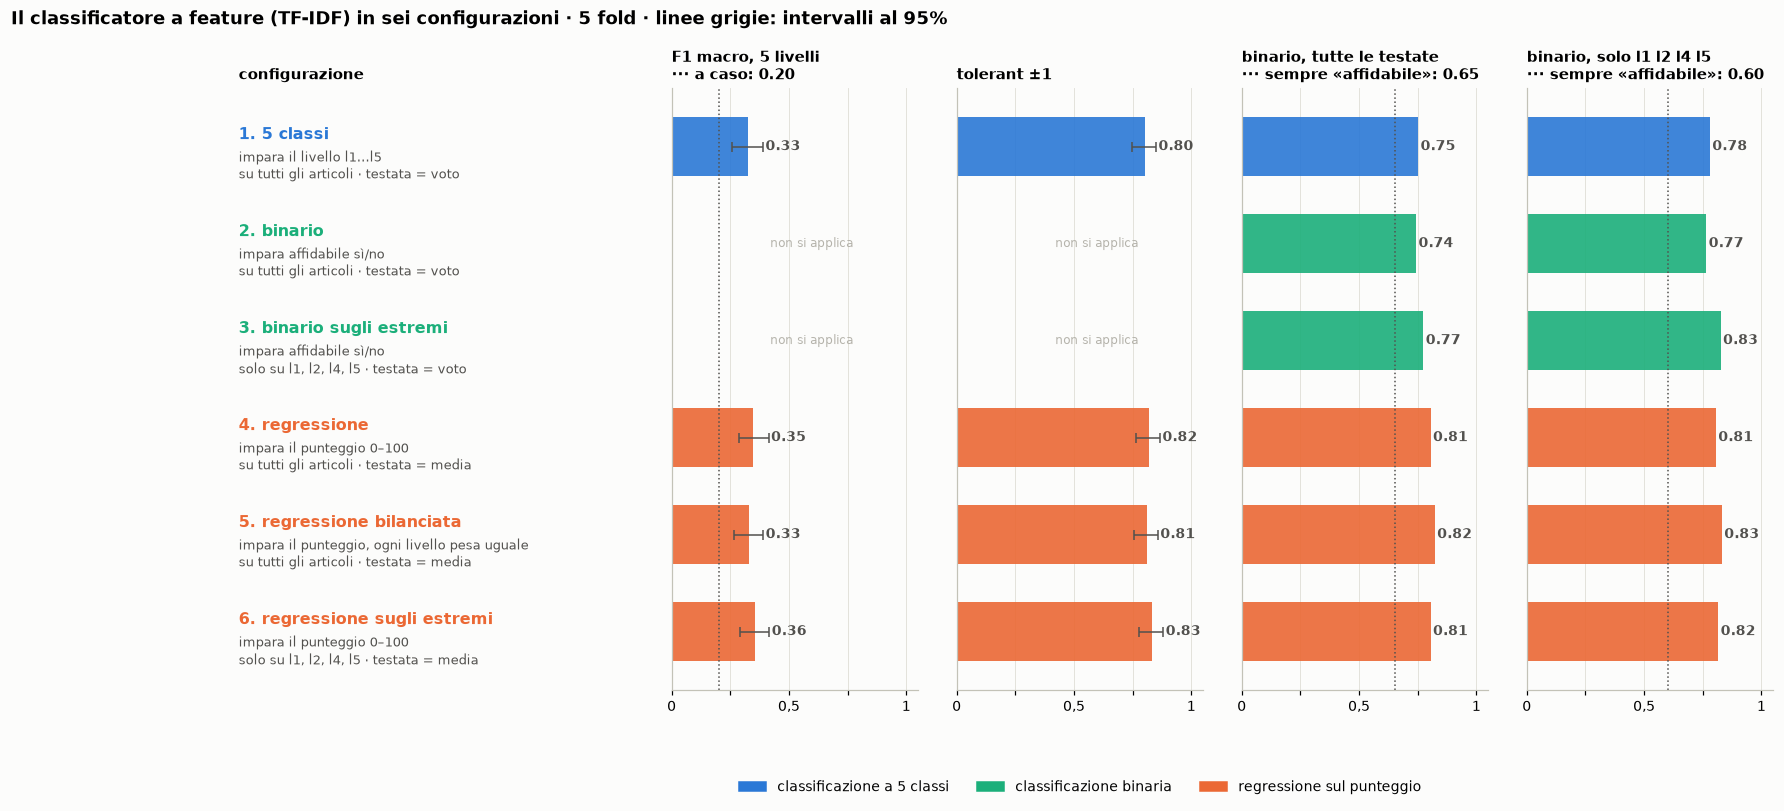

In [3]:
# 2.1 dagli articoli alle testate, le misure (salvate in Results/feature), il grafico
T = F.testate_da_articoli(pa, t); T.to_csv(OUT / "previsioni_testate.csv")
tab5, tab2 = F.misure_testate(T); tab5.to_csv(OUT / "cinque_livelli.csv"); tab2.to_csv(OUT / "binario.csv")
F.grafico_riassunto(T, tab5, tab2, "Il classificatore a feature (TF-IDF) in sei configurazioni · 5 fold · linee grigie: intervalli al 95%", OUT / "riassunto.png")